# Storm event in detail

One storm with everything we have, to see where the nearshore differences come
from:

1. **Forcing**: offshore waves at the goals, wind and water level (as given to
   the dynamic run).
2. **Buoys**: records against the offshore hindcast (closest goal), the
   metamodel without and with the wind correction, and the dynamic run (wind and
   water level): metrics, storm peaks, time series.
3. **Wind correction**: at a few buoys, the wind sea the correction sees, the
   wind, how developed the sea is, the wind–wave angle and `K`, against the
   training range (05b).
4. **Maps at the peak**: the dynamic run at every site of a map set, the
   metamodel without / with the correction minus it, and `K`.

The metamodel is read from the reconstruction cache (missing months are
computed, whole months). §3 recomputes the event without the cache
(`mm.wind_sea_diagnostics`). `K` is a tree model, so tiny batch differences can
move it: compared with the month-long cache it can differ a little.

**Prerequisites**: fitted models (06), wind correction (05b), the offshore
source (07a/b), the dynamic run of the event's year (08), processed buoys (03).

Netherlands, Xaver (4–7 Dec 2013), against the month-long cache: up to 0.10 in
`K` and 0.23 m in Hs at the buoys with the correction, 0.8 mm without it.

In [1]:
import os
import sys

# GDAL/PROJ data paths when the kernel was not started through `conda activate`
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from bluemath_tk.waves.hywaves.plots import plot_event_maps, plot_wind_sea_event
from utils import metamodel as mm
from utils import simulation as sim
from utils import validation as val
from utils import wind
from utils.config import load_goals, open_offshore_waves, open_water_level, open_wind
from utils.geometry import attach_site_meta

## Configuration

In [2]:
event = slice("2013-12-04", "2013-12-07")  # Xaver
offshore_name = "WHACS_cal"  # offshore_waves entry (the dynamic run's forcing)
mda_n = 550  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set at the buoys
map_set = "isobaths"  # metamodel set of the maps at the peak
show_buoys = [
    "buoy_Europlatform",
    "buoy_Brouwershavensegat",
    "buoy_AmelanderZeegat_1_1",
    "buoy_L91",
]

dynamic_path = sim.cases_dir("dynamic") / f"Dynamic_Cases_{offshore_name}_2013.nc"
wind_labels = {False: "Metamodel · wind off", True: "Metamodel · wind on"}
print(f"event   : {event.start} to {event.stop}")
print(f"dynamic : {dynamic_path} (exists: {dynamic_path.is_file()})")

event   : 2013-12-04 to 2013-12-07
dynamic : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_cal_2013.nc (exists: True)


## 1 · Forcing

Offshore waves at the goals, wind and water level, as given to the dynamic run.

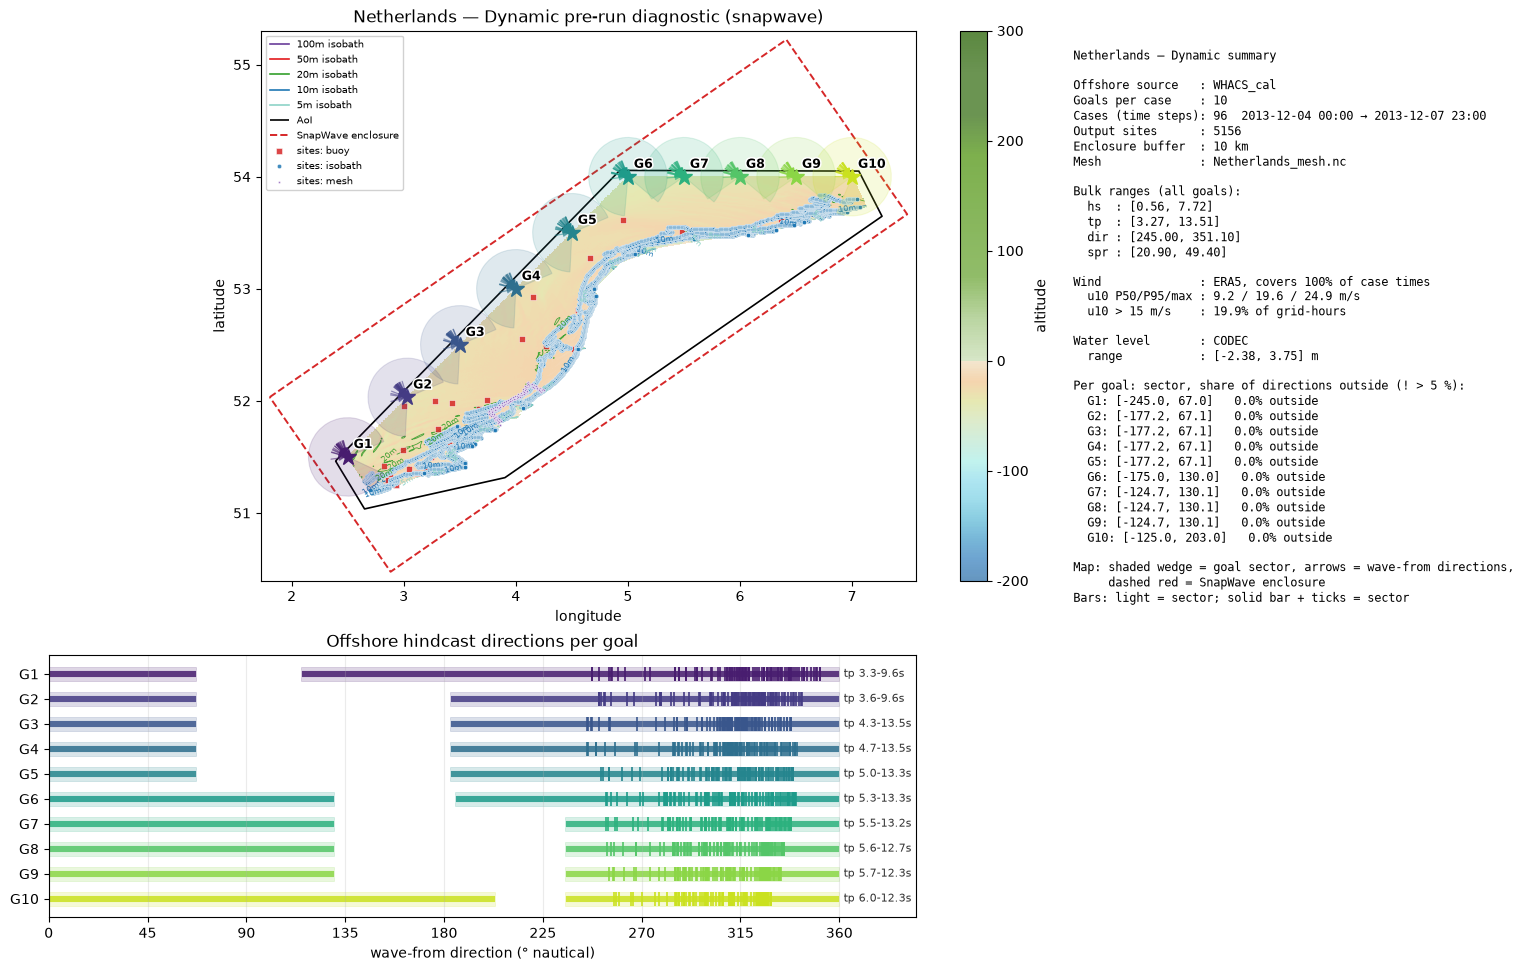

In [3]:
offshore = open_offshore_waves(offshore_name).sel(time=event).load()
setup = sim.HyWavesWrapperSetup.from_case(load_goals())
fig = setup.plot_dynamic_configuration(
    offshore,
    offshore_name=offshore_name,
    wind=open_wind(event),
    water_level=open_water_level(),
)
plt.show()

## 2 · Buoys

Buoy records in the event, the metamodel (cache) without and with the wind correction, the offshore hindcast at the closest goal and the dynamic run. Metrics: median over the buoys.

In [4]:
buoy = val.load_buoy_observations(event)
sites = list(buoy.sites.values)
show_buoys = show_buoys or list(buoy["hs"].max("time").to_series().nlargest(3).index)
print(f"{len(sites)} buoys with data; shown in detail: {show_buoys}")

# Resources for the reconstructions below (at most 75% of this machine)
res = mm.reconstruction_resources(
    event,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_name,
    wl="forcing",
    save_spectra=False,
    wind_correction=True,
)

19 buoys with data; shown in detail: ['buoy_Europlatform', 'buoy_Brouwershavensegat', 'buoy_AmelanderZeegat_1_1', 'buoy_L91']
Machine   48 cores, 406 GiB free of 503 GiB, no GPU -> at most 36 cores, 305 GiB (75%)
Request   buoys n=550 spectral (41 contributions/site), slice('2013-12-04', '2013-12-07', None): 0 of 38 site-months to compute, in 0 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 305 GiB
Spectra   not saved (save_spectra=True to keep them): ~0.0 GB on disk for these site-months, 16562 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


In [5]:
metamodel = {
    label: mm.reconstruct(
        event,
        mda_n,
        metamodel=mm_set,
        spectral=True,
        offshore_name=offshore_name,
        wl="forcing",
        save_spectra=False,
        wind_correction=on,
        resources=res,
    )
    for on, label in wind_labels.items()
}
dynamic = attach_site_meta(xr.open_dataset(dynamic_path).sel(time=event).load())
offshore_hindcast, _ = val.load_offshore_hindcast_at_buoys(
    event, sites, offshore_names=[offshore_name]
)
estimates = {
    **offshore_hindcast,
    **metamodel,
    val.DYNAMIC_REFERENCE_LABEL: dynamic.sel(sites=sites),
}

results = val.compare_all(
    buoy, estimates, variables=["hs", "tp"], reference_label="Buoy"
)
val.metrics_summary(results).groupby(["label", "model"])[
    ["n", "bias", "rmse", "r2"]
].median().round(3)

n   bias   rmse     r2
label model                                              
Hs    Dynamic SnapWave          96.0 -0.026  0.420  0.836
      Metamodel · wind off      96.0 -0.236  0.457  0.814
      Metamodel · wind on       96.0  0.046  0.432  0.876
      WHACS_cal (closest goal)  96.0  0.072  0.710  0.861
Tp    Dynamic SnapWave          96.0 -1.209  2.659  0.046
      Metamodel · wind off      96.0 -0.776  3.014 -0.165
      Metamodel · wind on       96.0 -0.990  2.902  0.017
      WHACS_cal (closest goal)  96.0 -0.882  2.679  0.063

Storm peak at each buoy: the largest Hs of each source in the event, its
difference to the buoy peak (m) and its lag (h, positive = later than the buoy).

In [6]:
peaks = val.event_peaks(buoy, estimates)
diffs = peaks[[c for c in peaks if c.endswith(" - Buoy") or c.endswith(" lag (h)")]]
display(diffs.median().round(2).to_frame("median over the buoys").T)
peaks[["Buoy", *[c for c in peaks if c.endswith(" - Buoy")]]].round(2)

,WHACS_cal (closest goal) - Buoy,WHACS_cal (closest goal) lag (h),Metamodel · wind off - Buoy,Metamodel · wind off lag (h),Metamodel · wind on - Buoy,Metamodel · wind on lag (h),Dynamic SnapWave - Buoy,Dynamic SnapWave lag (h)
median over the buoys,-0.3,-2.0,-0.67,-1.0,-0.01,-3.0,-0.62,-1.0


,Buoy,WHACS_cal (closest goal) - Buoy,Metamodel · wind off - Buoy,Metamodel · wind on - Buoy,Dynamic SnapWave - Buoy
buoy_AWG,5.46,2.02,0.30,0.47,-1.24
buoy_Amelander31,2.09,5.05,0.50,0.98,0.21
buoy_AmelanderZeegat_1_1,7.44,-0.30,-1.14,-0.75,-1.31
buoy_Brouwershavensegat,4.48,-0.32,-0.82,-0.60,-0.62
buoy_CadzandBoei,2.68,0.77,-0.18,0.09,-0.48
buoy_EierlandseGat,6.23,0.29,-0.35,0.07,0.01
buoy_EurogeulE13,4.92,-0.77,-0.88,-0.14,-0.59
buoy_EurogeulE5,4.52,-0.36,-0.40,0.41,-0.05
buoy_Europlatform,4.79,-0.63,-0.67,-0.01,-0.44
buoy_GoereeLichteiland,4.74,-0.59,-0.71,0.01,-0.42


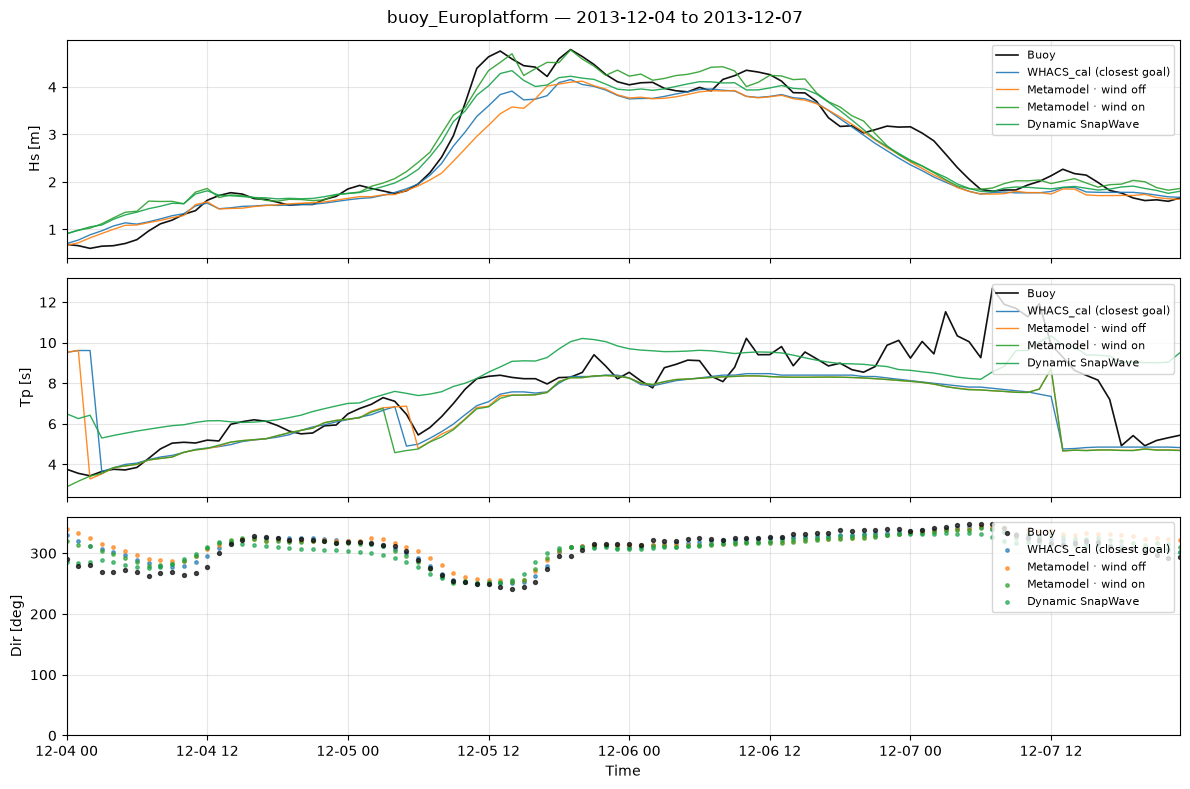

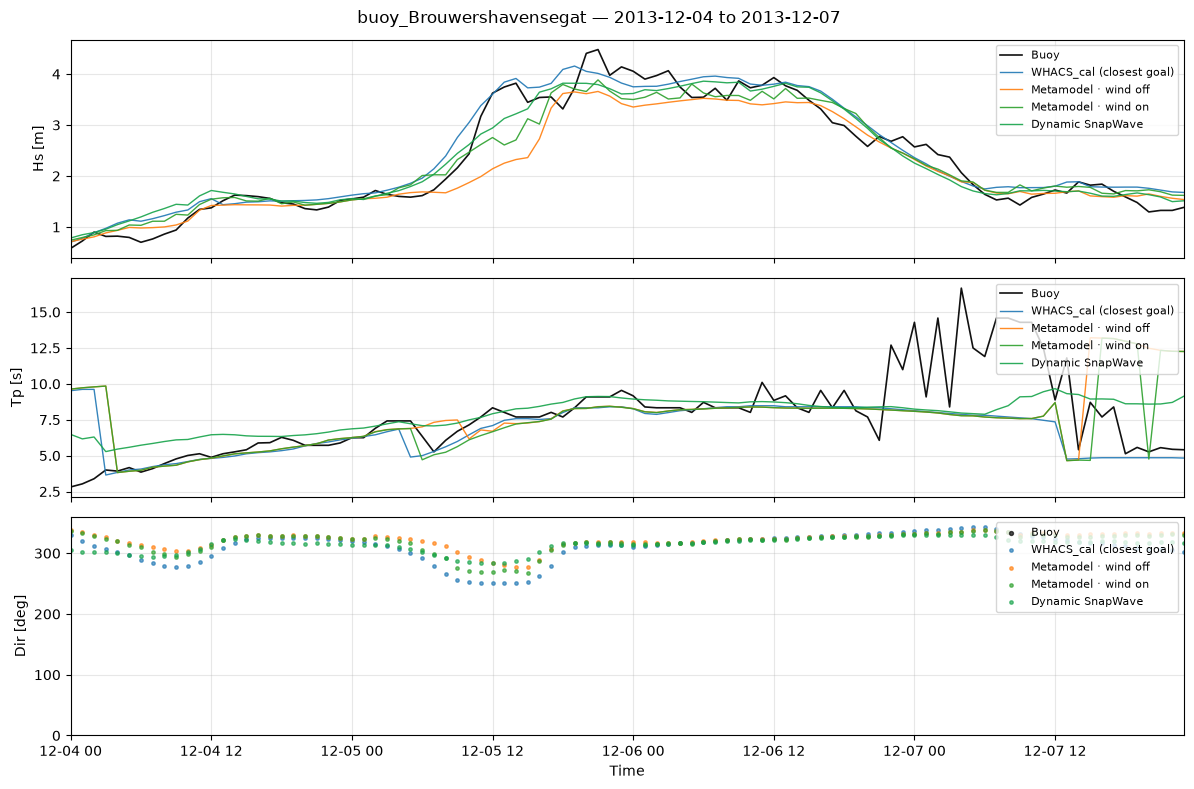

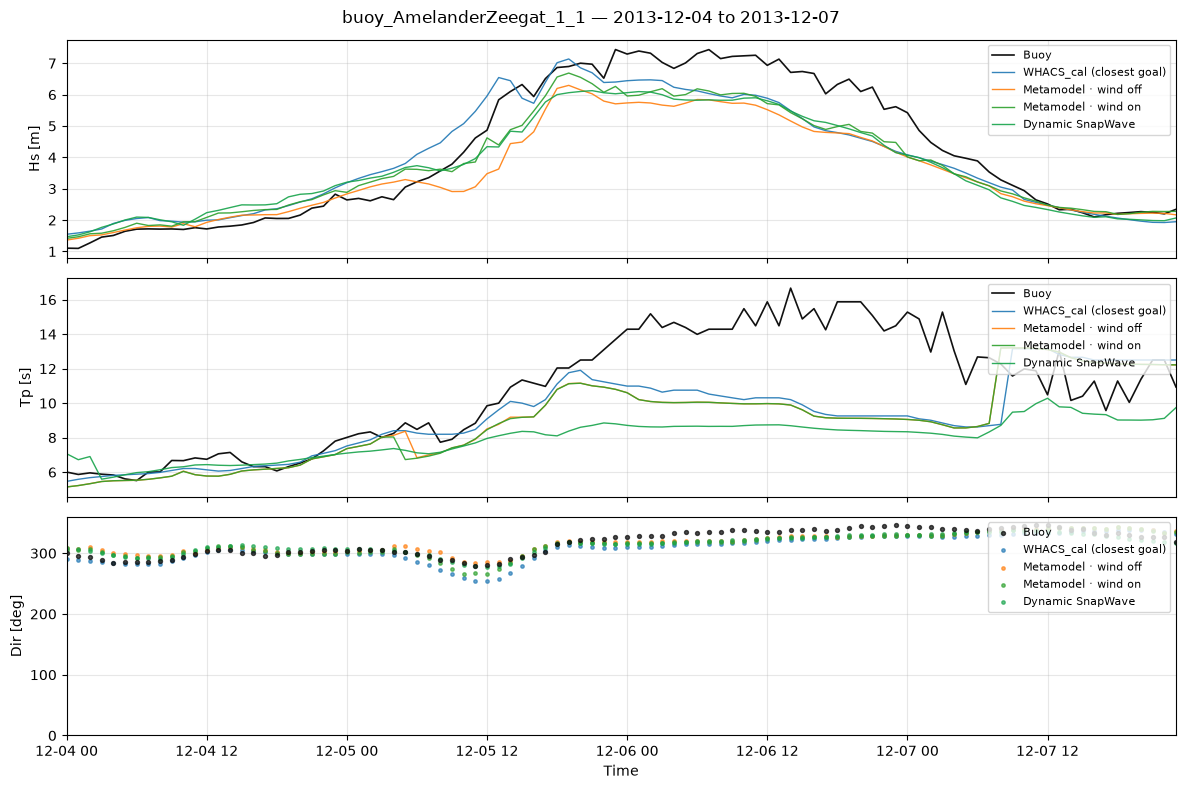

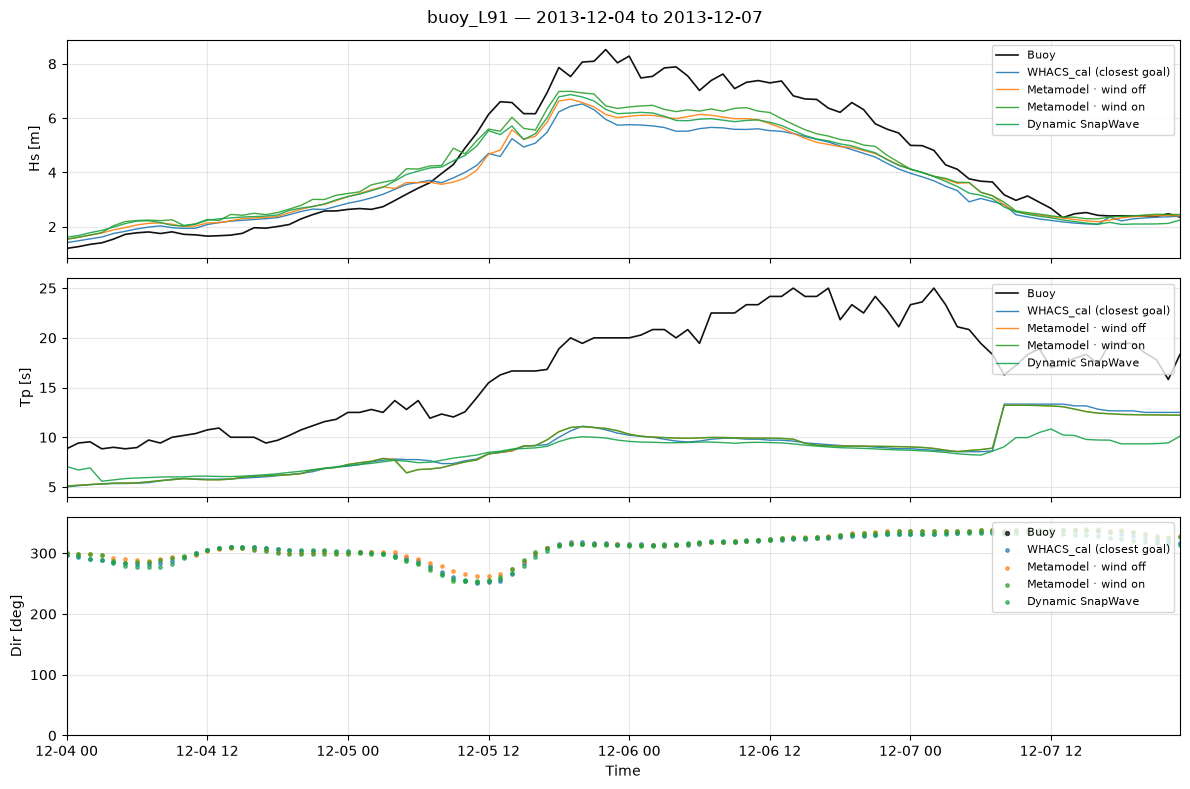

In [7]:
for site in show_buoys:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=["hs", "tp", "dir"])
    plt.suptitle(f"{site} — {event.start} to {event.stop}")
    plt.show()

## 3 · What the wind correction sees

At each buoy: Hs of every source; the wind sea the correction scales
(`Hs_ws`, from the contributions whose offshore forcing is a wind sea) and the
wind; how developed the wind sea is (g·Hs_ws/U², 0.24 = fully developed) and
the wind–wave angle, against the training range of 05b; and `K`.

INFO:bluemath_tk.core.resources:_goal_pcs: 1/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 2/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 3/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 4/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 5/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 6/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 7/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 8/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 9/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 10/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 11/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 12/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 13/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 14/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 15/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 16/33 jobs done
INFO:bluemath_tk.core.resources:_goal_pcs: 17/33 jobs done
INFO:b

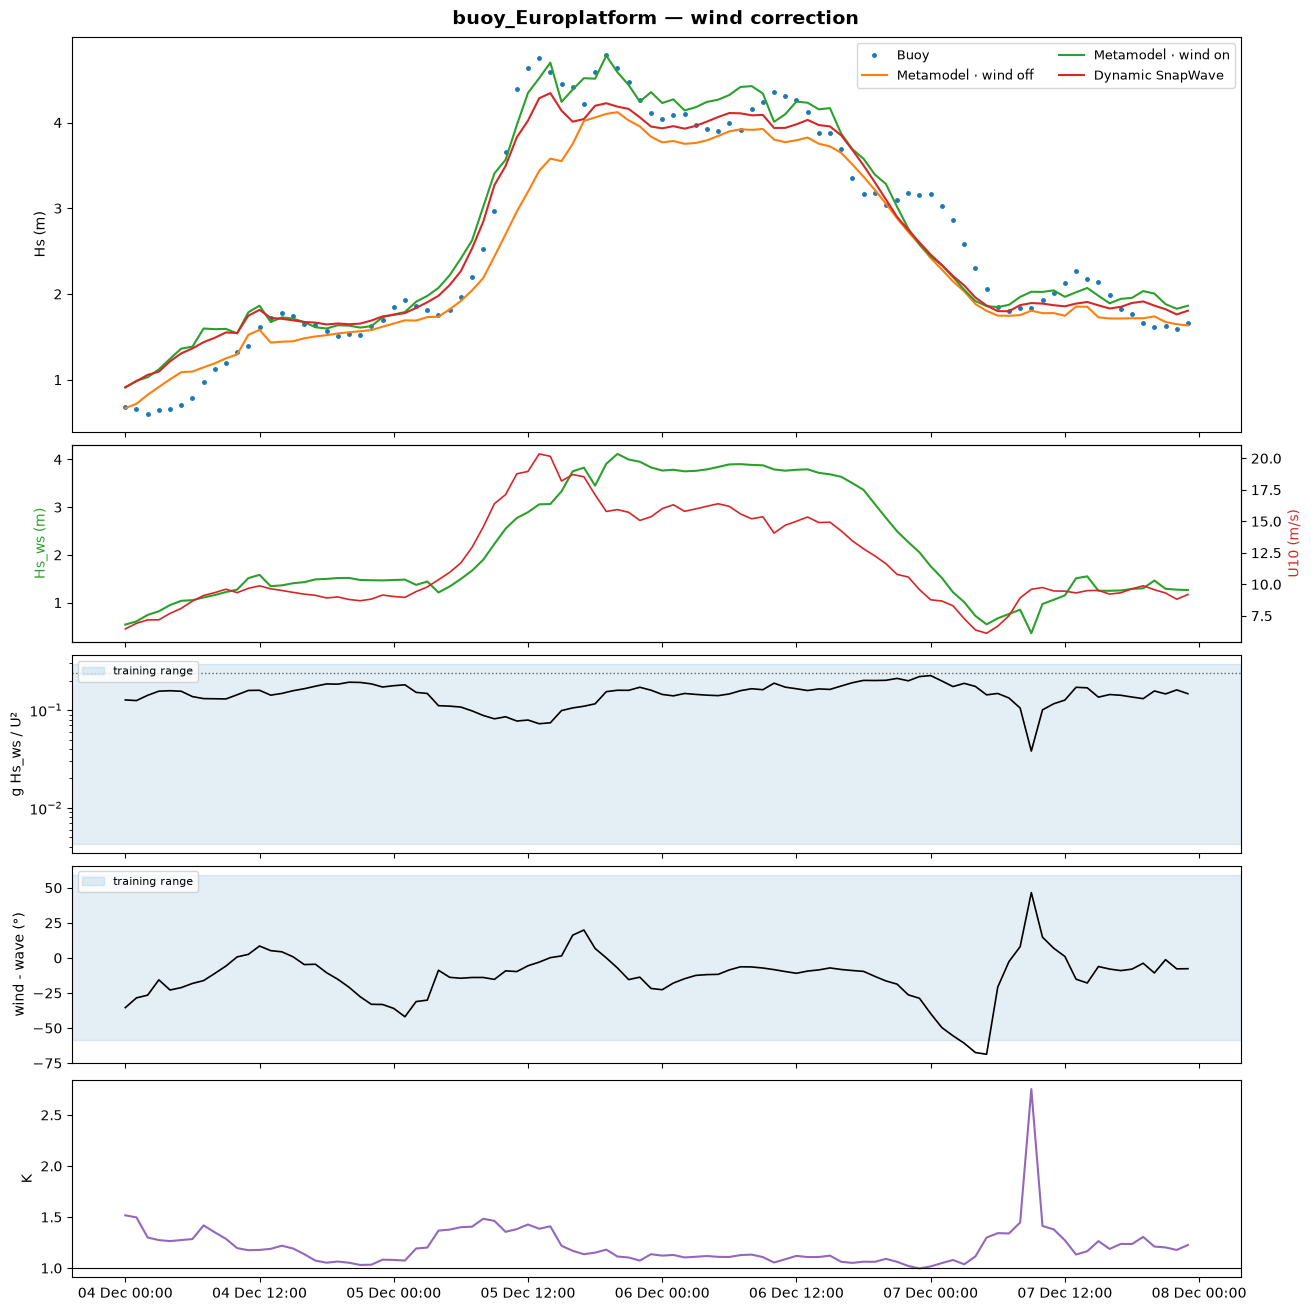

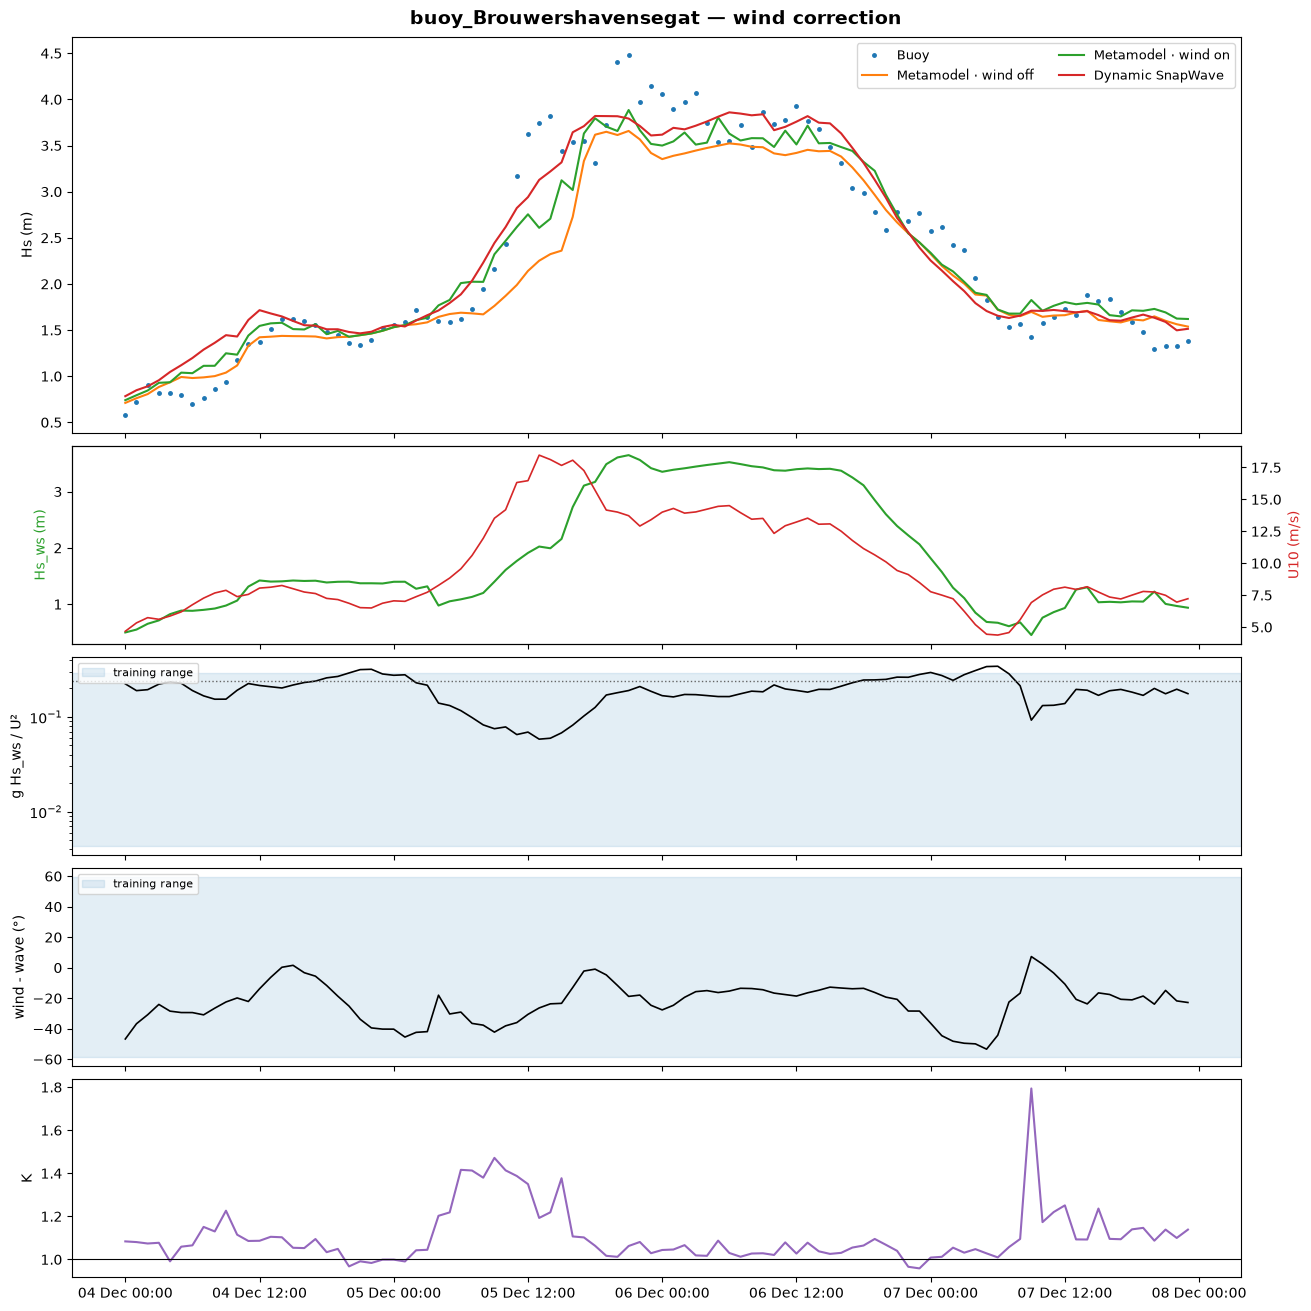

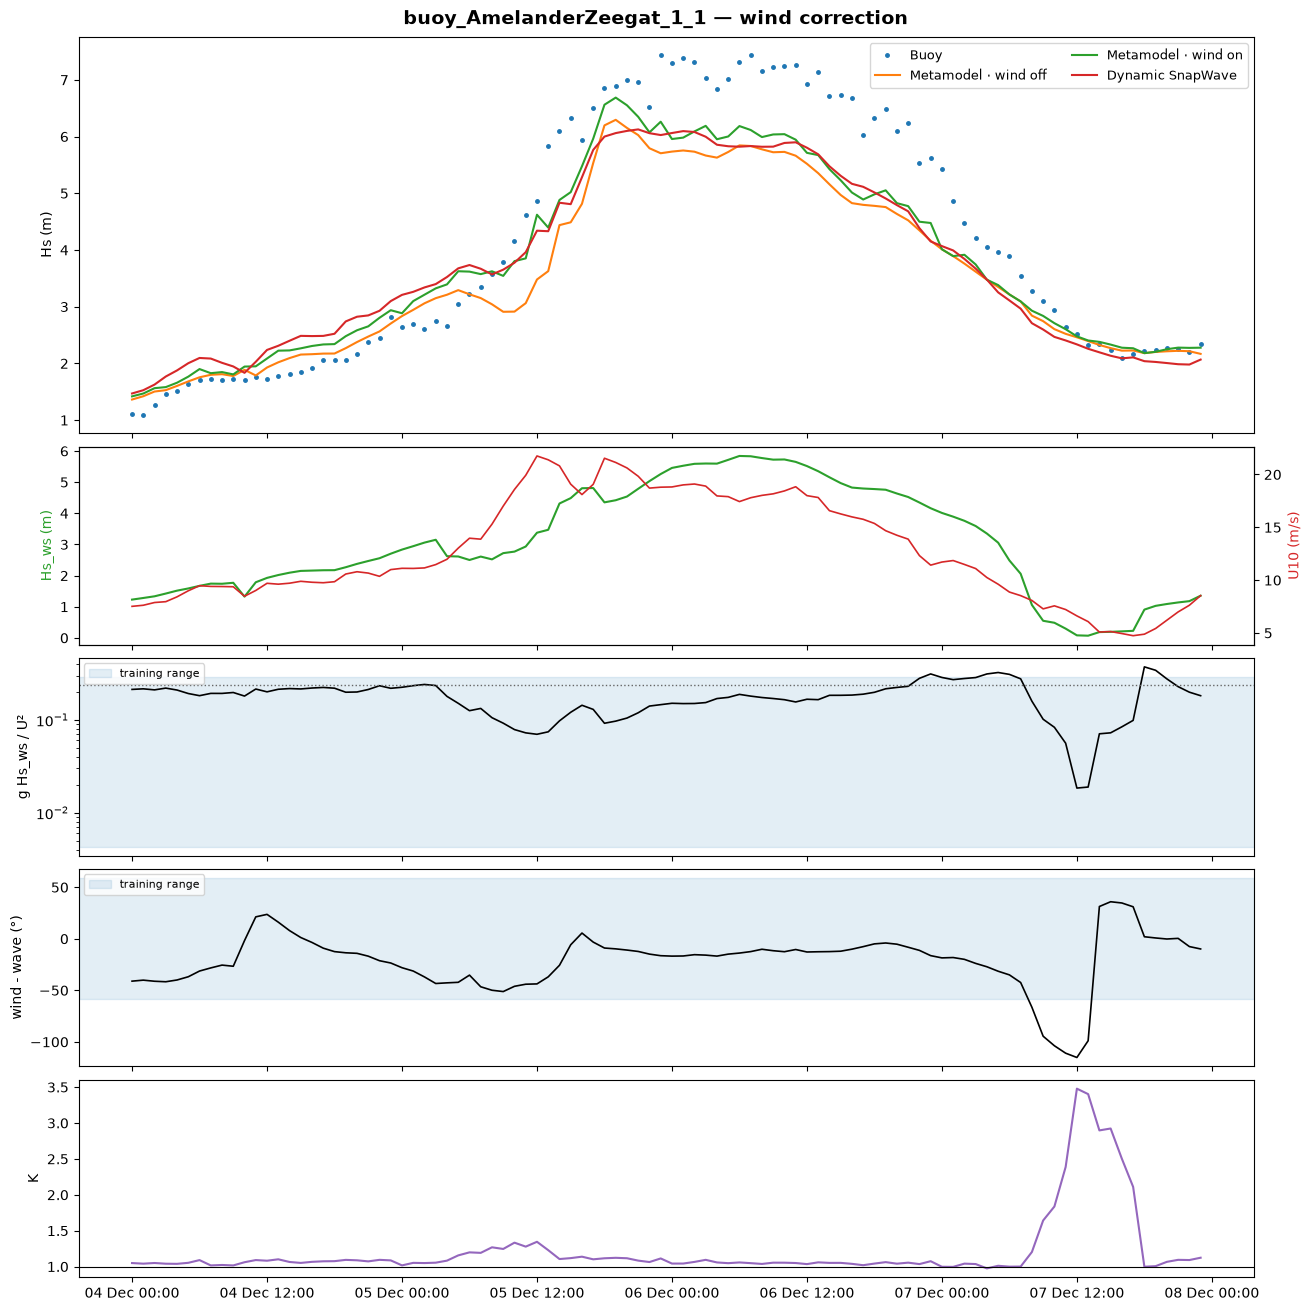

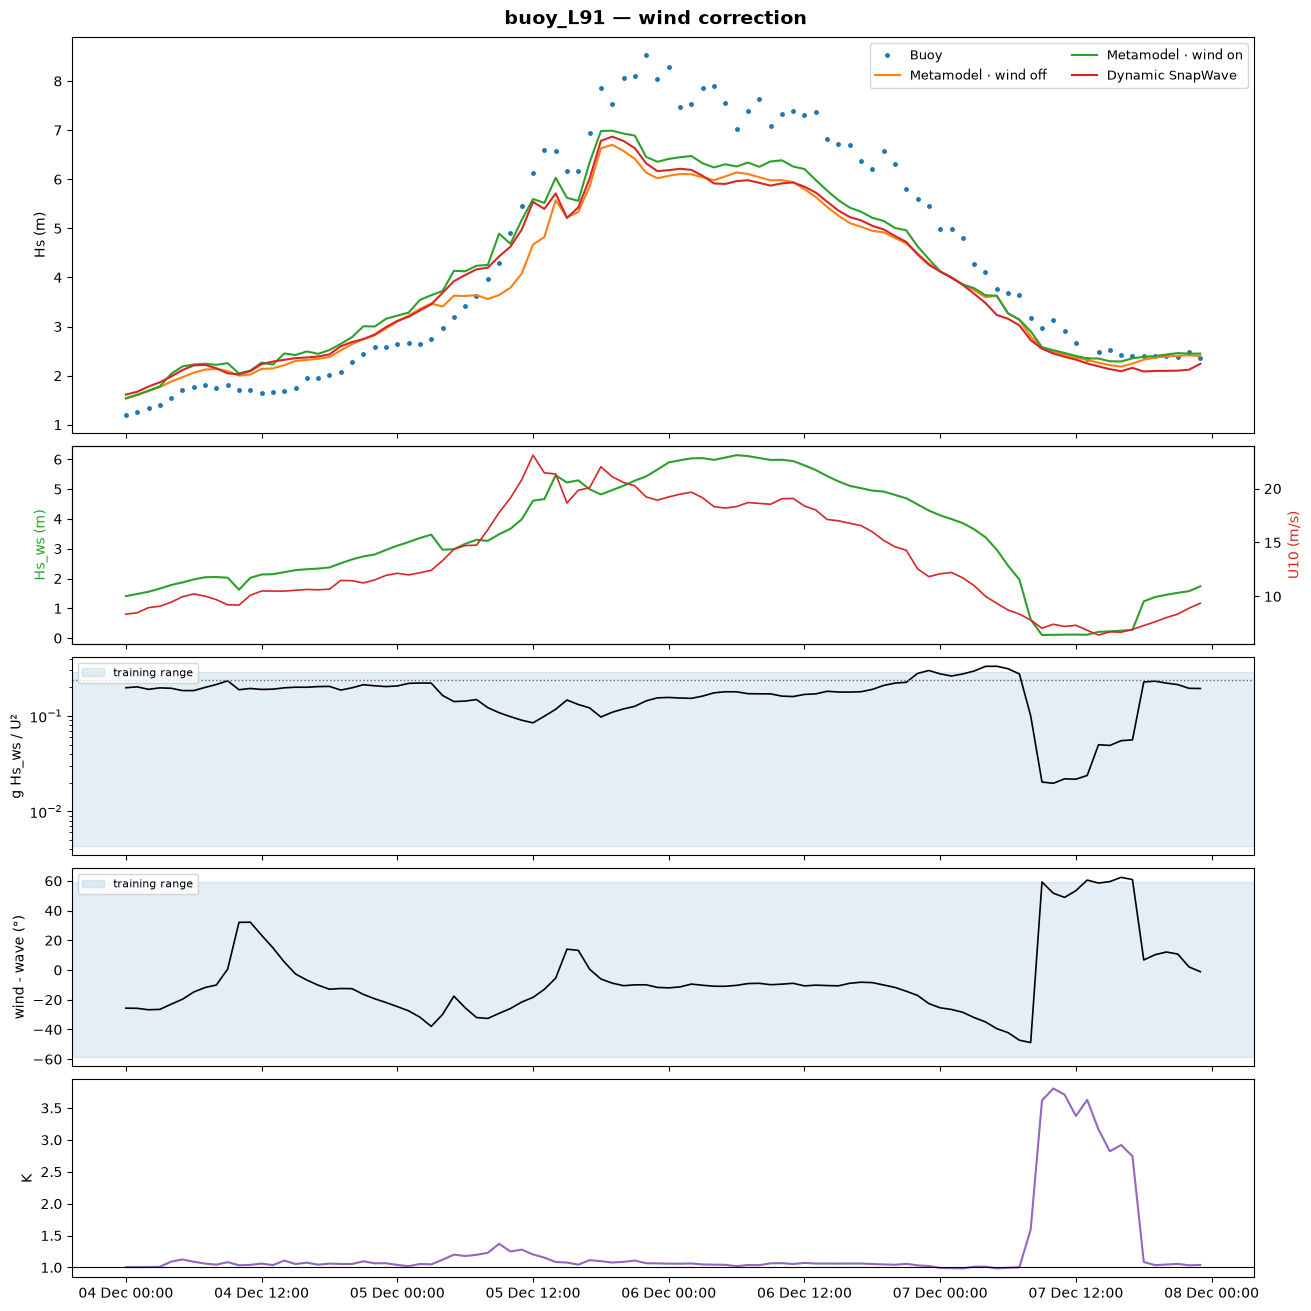

In [8]:
ws = mm.wind_sea_diagnostics(
    event,
    mda_n,
    metamodel=mm_set,
    resources=res,
    offshore_name=offshore_name,
    wl="forcing",
)
ranges = wind.training_range()
for site in show_buoys:
    hs = {"Buoy": buoy["hs"].sel(sites=site)}
    hs.update(
        {
            label: ds["hs"].sel(sites=site)
            for label, ds in estimates.items()
            if label in metamodel or label == val.DYNAMIC_REFERENCE_LABEL
        }
    )
    fig = plot_wind_sea_event(
        ws.sel(sites=site), hs, ranges, title=f"{site} — wind correction"
    )
    plt.show()

## 4 · Maps at the peak

The hour of the event with the highest median dynamic Hs over the `map_set`
sites: the dynamic run, the metamodel without / with the correction minus it,
and `K`. The map set is reconstructed for the event's months if not cached yet
(resources below).

In [9]:
map_res = mm.reconstruction_resources(
    event,
    mda_n,
    metamodel=map_set,
    spectral=True,
    offshore_name=offshore_name,
    wl="forcing",
    save_spectra=False,
    wind_correction=True,
)

Machine   48 cores, 408 GiB free of 503 GiB, no GPU -> at most 36 cores, 306 GiB (75%)
Request   isobaths n=550 spectral (41 contributions/site), slice('2013-12-04', '2013-12-07', None): 0 of 4971 site-months to compute, in 0 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 306 GiB
Spectra   not saved (save_spectra=True to keep them): ~0.0 GB on disk for these site-months, 16562 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


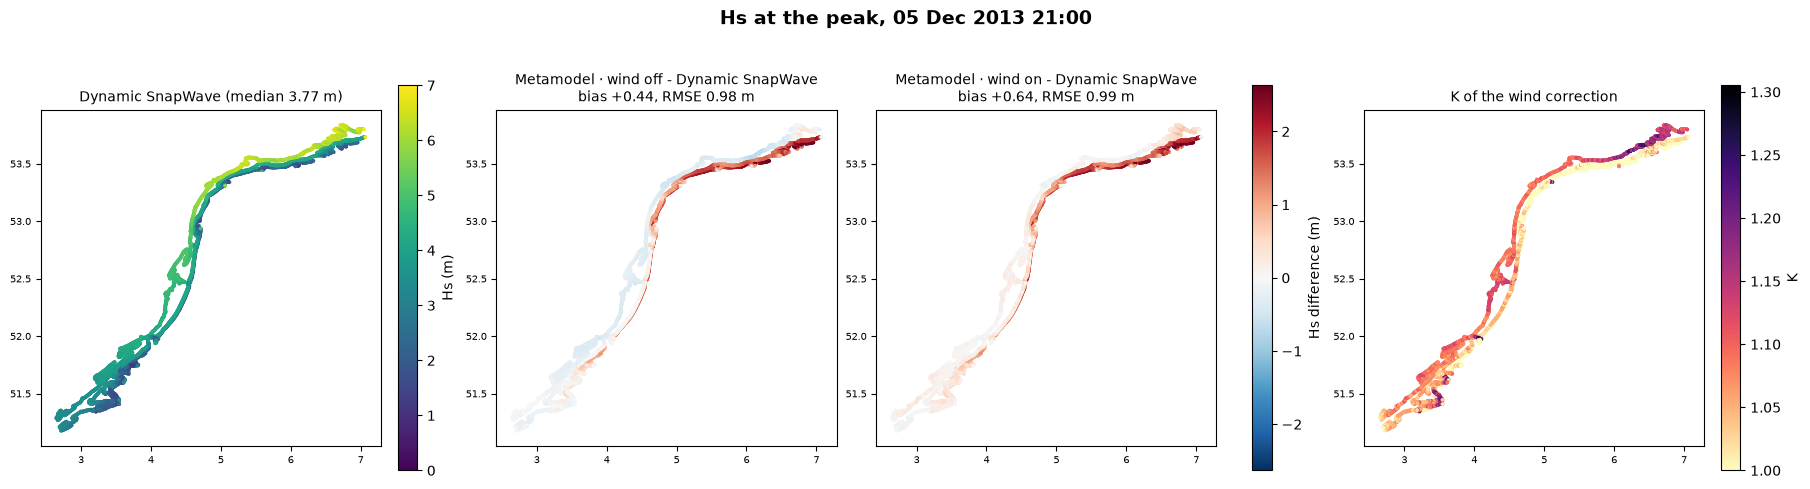

In [10]:
maps = {
    label: mm.reconstruct(
        event,
        mda_n,
        metamodel=map_set,
        spectral=True,
        offshore_name=offshore_name,
        wl="forcing",
        save_spectra=False,
        wind_correction=on,
        resources=map_res,
    )
    for on, label in wind_labels.items()
}
map_dynamic = dynamic["hs"].sel(sites=maps[wind_labels[False]].sites.values)
peak = map_dynamic.median("sites").idxmax("time").values
fig = plot_event_maps(
    map_dynamic.sel(time=peak),
    {label: ds["hs"].sel(time=peak) for label, ds in maps.items()},
    k=maps[wind_labels[True]]["wind_k"].sel(time=peak),
    reference_label=val.DYNAMIC_REFERENCE_LABEL,
    title=f"Hs at the peak, {pd.Timestamp(peak):%d %b %Y %H:%M}",
)
plt.show()